# Match performance with contextual xG

## tl;dr

**Chelsea 2–2 Tottenham Hotspur, Stamford Bridge, May 2, 2016.** Tottenham led 2–0 at half-time;
Chelsea scored twice after the break. This held-out test match provides a useful example of how the
scoreline and chance quality can tell different stories.

The frozen contextual model assigns **Chelsea 0.69 npxG from 13 shots** and **Tottenham 2.46 npxG
from 16 shots**. These totals come from the original saved `stack_identity` predictions, checked
against their SHA-256 hash. All four goals were non-penalty goals.

This notebook contains a team summary, shot maps, a cumulative xG timeline, a half-by-half
comparison, a chance ranking and four shot freeze frames. It loads predictions and does not fit models.

## Context and methods

The match was selected as an illustration of a second-half comeback, not as evidence that the model
outperforms another provider. It falls after the project's April 11, 2016 test cutoff.

### Key assumptions

- `npxG` means the sum of predicted goal probabilities for **non-penalty shots**.
- The primary prediction is the frozen stack with identity calibration. StatsBomb xG is a labeled comparator.
- Shots are joined **one-to-one by `shot_id`**, never by row position or player name.
- Shot coordinates use the StatsBomb 120-by-80 pitch. Each attacking team is displayed attacking right.
- The timeline uses elapsed match time, retaining first-half stoppage time and omitting the half-time interval.
  This prevents late first-half events from appearing after second-half events. Goal labels use the football clock.
- Goals minus npxG describes this match's outcomes. It does not establish persistent finishing skill or win probability.

Run this notebook independently on a CPU kernel. A GPU and the training notebook's in-memory objects are unnecessary.

### 1. Imports and plotting style

Required packages are `numpy`, `pandas`, `pyarrow`, `matplotlib`, `requests` and the notebook's IPython kernel.
If an import is missing, run `%pip install numpy pandas pyarrow matplotlib requests` in that kernel first.

In [ ]:
import gzip
import hashlib
import json
import os
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Arc, Circle, Rectangle
import numpy as np
import pandas as pd
import requests
from IPython import get_ipython
from IPython.display import Markdown, display

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 180, "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.facecolor": "#ffffff", "figure.facecolor": "#ffffff",
    "text.color": "#172033", "axes.labelcolor": "#334155",
})


### 2. Paths and match selection

On Colab, the default artifact directory is the existing Drive project. Mounting Drive is the only
setup interaction needed. Locally, point `ARTIFACT_ROOT` at a copy of that project or set the
`CONTEXTUAL_XG_ARTIFACT_ROOT` environment variable. The folder must contain the original
`models/<commit>/final_evaluation/` files. The repository's `results/` exports alone do not include shot predictions.

The cache holds only public match metadata and events. All output exports are optional and separate
from the frozen model artifacts. After downloading the two public inputs once, the notebook can run offline.

In [3]:
COMMIT = "3bfbffe1de5750ebd47d770be0bb924a10cde54f"
MATCH_ID = 3754092
COMPETITION_ID = 2
SEASON_ID = 27
EXPECTED_DATE = "2016-05-02"
EXPECTED_TEAMS = ("Chelsea", "Tottenham Hotspur")
PREDICTION_COLUMN = "stack_identity"

ARTIFACT_ROOT = Path(os.environ.get(
    "CONTEXTUAL_XG_ARTIFACT_ROOT", "/content/drive/MyDrive/xg-python"
)).expanduser()
CACHE_DIR = Path(os.environ.get(
    "CONTEXTUAL_XG_MATCH_CACHE", str(Path(tempfile.gettempdir()) / "contextual-xg-match-analysis")
)) / COMMIT
SAVE_OUTPUTS = False
OUTPUT_DIR = Path.cwd() / "match_performance_outputs" / str(MATCH_ID)

if str(ARTIFACT_ROOT).startswith("/content/drive/") and not Path("/content/drive/MyDrive").is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

FINAL_DIR = ARTIFACT_ROOT / "models" / COMMIT / "final_evaluation"
DATA_BASE = f"https://raw.githubusercontent.com/hudl/open-data/{COMMIT}/data"
MATCHES_URL = f"{DATA_BASE}/matches/{COMPETITION_ID}/{SEASON_ID}.json"
EVENTS_URL = f"{DATA_BASE}/events/{MATCH_ID}.json"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
figures = {}

print("Saved predictions:", FINAL_DIR)
print("Public-data cache:", CACHE_DIR)
print("Optional exports enabled:", SAVE_OUTPUTS)


Mounted at /content/drive
Saved predictions: /content/drive/MyDrive/xg-python/models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation
Public-data cache: /tmp/contextual-xg-match-analysis/3bfbffe1de5750ebd47d770be0bb924a10cde54f
Optional exports enabled: False


## Data

### 3. Verify and read the frozen test predictions

Read only the IDs, split and stack probability needed for the report. Verify the complete prediction
file before filtering the match. Missing or changed artifacts raise an error; there is no substitution
of StatsBomb's probabilities for the project model.

In [4]:
def sha256_file(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

required_files = ["frozen_manifest.json", "test_result.json", "test_model_predictions.parquet"]
missing = [name for name in required_files if not (FINAL_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} under {FINAL_DIR}. Mount Drive or update ARTIFACT_ROOT to the original project."
    )

manifest = json.loads((FINAL_DIR / "frozen_manifest.json").read_text())
test_result = json.loads((FINAL_DIR / "test_result.json").read_text())
if manifest["data_source"] != {"repository": "hudl/open-data", "commit": COMMIT}:
    raise ValueError("The manifest does not use the expected pinned data snapshot.")
if manifest["selected_model"] != PREDICTION_COLUMN or manifest["calibration"]["method"] != "identity":
    raise ValueError("Expected the original stack with identity calibration.")
if sha256_file(FINAL_DIR / "frozen_manifest.json") != test_result["frozen_manifest_sha256"]:
    raise ValueError("The test result and frozen manifest do not match.")

prediction_relative = test_result["artifacts"]["test_model_predictions.parquet"]
expected_hash = test_result["artifact_sha256"][prediction_relative]
prediction_path = FINAL_DIR / "test_model_predictions.parquet"
if sha256_file(prediction_path) != expected_hash:
    raise ValueError("The test prediction file differs from the original frozen artifact.")

predictions = pd.read_parquet(
    prediction_path, columns=["shot_id", "match_id", "split", PREDICTION_COLUMN]
)
if (len(predictions) != manifest["evaluation_protocol"]["expected_test_shots"]
        or predictions["shot_id"].isna().any() or not predictions["shot_id"].is_unique
        or not predictions["split"].eq("test").all()):
    raise ValueError("Test prediction coverage, IDs or split labels are invalid.")
probabilities = predictions[PREDICTION_COLUMN].to_numpy(dtype=float)
if not np.isfinite(probabilities).all() or ((probabilities < 0) | (probabilities > 1)).any():
    raise ValueError("Invalid saved probabilities.")
match_predictions = predictions.loc[predictions["match_id"].eq(MATCH_ID)].copy()
if match_predictions.empty:
    raise ValueError("The chosen match is absent from the saved held-out predictions.")
print(f"Frozen hash verified. Selected {len(match_predictions)} shots from {len(predictions):,} test predictions.")


Frozen hash verified. Selected 29 shots from 6,868 test predictions.


### 4. Load the pinned public match metadata and events

Only one competition-season match catalogue and this match's events are requested when the cache
is empty. Player and team names come from these events. The source commit is fixed, so a later
StatsBomb data update cannot silently change the example.

In [5]:
metadata_cache = CACHE_DIR / f"match-{MATCH_ID}.json"
events_cache = CACHE_DIR / f"events-{MATCH_ID}.json.gz"

if metadata_cache.is_file():
    match = json.loads(metadata_cache.read_text())
else:
    response = requests.get(MATCHES_URL, timeout=(15, 60))
    response.raise_for_status()
    candidates = [row for row in response.json() if row["match_id"] == MATCH_ID]
    if len(candidates) != 1:
        raise ValueError("The selected match was not uniquely found in the pinned catalogue.")
    match = candidates[0]
    metadata_cache.write_text(json.dumps(match, indent=2), encoding="utf-8")

if events_cache.is_file():
    with gzip.open(events_cache, "rt", encoding="utf-8") as stream:
        events = json.load(stream)
else:
    response = requests.get(EVENTS_URL, timeout=(15, 60))
    response.raise_for_status()
    events = response.json()
    with gzip.open(events_cache, "wt", encoding="utf-8") as stream:
        json.dump(events, stream, separators=(",", ":"))

home_name = match["home_team"]["home_team_name"]
away_name = match["away_team"]["away_team_name"]
team_order = [home_name, away_name]
if (match["match_id"] != MATCH_ID or match["match_date"] != EXPECTED_DATE
        or tuple(team_order) != EXPECTED_TEAMS):
    raise ValueError("Cached match metadata does not describe the selected fixture.")
if pd.Timestamp(match["match_date"]) < pd.Timestamp(manifest["evaluation_protocol"]["test_from"]):
    raise ValueError("This example must use the original held-out test period.")
if not isinstance(events, list) or not events:
    raise ValueError("Missing or invalid event records.")

team_colors = {home_name: "#2563eb", away_name: "#b45309"}
team_styles = {home_name: "-", away_name: "--"}
team_ids = {home_name: match["home_team"]["home_team_id"], away_name: match["away_team"]["away_team_id"]}
full_score = {home_name: int(match["home_score"]), away_name: int(match["away_score"])}
match_title = f"{home_name} {full_score[home_name]}–{full_score[away_name]} {away_name}"
print(f"{match_title} | {match['match_date']} | {match['stadium']['name']}")
print(f"Loaded {len(events):,} pinned events.")


Chelsea 2–2 Tottenham Hotspur | 2016-05-02 | Stamford Bridge
Loaded 3,299 pinned events.


### 5. Build a checked shot table and a period-aware clock

The official score includes all goals. The xG analysis excludes penalties. This fixture contains
no penalties or own goals, so the two goal counts reconcile directly. Both teams' duplicate Half End
records are reduced to one maximum duration per period.

In [6]:
def clock_seconds(timestamp):
    hours, minutes, seconds = timestamp.split(":")
    return int(hours) * 3600 + int(minutes) * 60 + float(seconds)

def football_clock(period, period_seconds):
    normal_period_minutes = 45
    minutes, seconds = divmod(int(period_seconds), 60)
    base = 45 * (period - 1)
    if minutes >= normal_period_minutes:
        return f"{base + 45}+{minutes - 45}:{seconds:02d}"
    return f"{base + minutes}:{seconds:02d}"

period_durations = {}
for period in (1, 2):
    period_ends = [clock_seconds(e["timestamp"]) for e in events
                   if e["period"] == period and e["type"]["name"] == "Half End"]
    if not period_ends:
        raise ValueError(f"No Half End event for period {period}.")
    period_durations[period] = max(period_ends)
period_offsets = {1: 0., 2: period_durations[1]}
half_time = period_durations[1] / 60
full_time = sum(period_durations.values()) / 60

records = []
shot_events = {}
for event in events:
    if event["type"]["name"] != "Shot":
        continue
    shot = event["shot"]
    if shot["type"]["name"] == "Penalty":
        continue
    period = event["period"]
    if period not in (1, 2):
        raise ValueError("This example expects a two-half league fixture without extra time.")
    elapsed = clock_seconds(event["timestamp"])
    shot_events[event["id"]] = event
    records.append({
        "shot_id": event["id"], "event_index": event["index"], "period": period,
        "clock": football_clock(period, elapsed),
        "elapsed_minute": (period_offsets[period] + elapsed) / 60,
        "team_id": event["team"]["id"], "team": event["team"]["name"],
        "player": event.get("player", {}).get("name", "Unknown player"),
        "shot_x": float(event["location"][0]), "shot_y": float(event["location"][1]),
        "body_part": shot["body_part"]["name"], "outcome": shot["outcome"]["name"],
        "is_goal": shot["outcome"]["name"] == "Goal",
        "statsbomb_xg": shot.get("statsbomb_xg", np.nan),
    })

observed_shots = pd.DataFrame.from_records(records)
if (observed_shots["shot_id"].isna().any() or not observed_shots["shot_id"].is_unique
        or set(observed_shots["shot_id"]) != set(match_predictions["shot_id"])):
    raise ValueError("The public non-penalty shot IDs and saved prediction IDs differ.")
shots = observed_shots.merge(
    match_predictions[["shot_id", PREDICTION_COLUMN]], on="shot_id", how="left", validate="one_to_one"
).rename(columns={PREDICTION_COLUMN: "model_xg"}).sort_values("event_index").reset_index(drop=True)
if not shots["elapsed_minute"].is_monotonic_increasing:
    raise ValueError("The period-aware timeline is not chronological.")
if not set(shots["team"]) == set(team_order):
    raise ValueError("Unexpected team labels in the shot table.")
if not shots["team"].map(team_ids).eq(shots["team_id"]).all():
    raise ValueError("Team IDs and names do not agree with match metadata.")
if not np.isfinite(shots[["model_xg", "statsbomb_xg", "shot_x", "shot_y"]].to_numpy()).all():
    raise ValueError("A chart input or benchmark prediction is missing or invalid.")
if not shots["statsbomb_xg"].between(0, 1).all():
    raise ValueError("Invalid StatsBomb benchmark probabilities.")
if not (shots["shot_x"].between(0, 120).all() and shots["shot_y"].between(0, 80).all()):
    raise ValueError("An out-of-bounds shot needs an explicit plotting policy.")
if shots["is_goal"].groupby(shots["team"]).sum().reindex(team_order).to_dict() != full_score:
    raise ValueError("Official score and non-penalty goal events differ; account for penalties or own goals.")

shots["cumulative_xg"] = shots.groupby("team", sort=False)["model_xg"].cumsum()
print(f"Joined {len(shots)} non-penalty shots one-to-one. Four observed goals match the official score.")
print(f"First half: {half_time:.2f} elapsed minutes; both halves: {full_time:.2f} elapsed minutes.")


Joined 29 non-penalty shots one-to-one. Four observed goals match the official score.
First half: 48.04 elapsed minutes; both halves: 99.94 elapsed minutes.


## Results

### 6. Team summary

Compare totals and average chance quality. The final score is level, but the chance totals and scoring margins differ.
These are single-match outcomes rather than estimates of repeatable finishing ability.

In [7]:
summary = shots.groupby("team").agg(
    shots=("shot_id", "size"), non_penalty_goals=("is_goal", "sum"),
    npxg=("model_xg", "sum"), statsbomb_npxg=("statsbomb_xg", "sum"),
).reindex(team_order)
summary["npxg_per_shot"] = summary["npxg"] / summary["shots"]
summary["goals_minus_npxg"] = summary["non_penalty_goals"] - summary["npxg"]
np.testing.assert_allclose(summary["npxg"].sum(), shots["model_xg"].sum(), rtol=0, atol=1e-12)

summary_display = summary.rename(columns={
    "shots": "Shots", "non_penalty_goals": "NP goals", "npxg": "Model npxG",
    "statsbomb_npxg": "StatsBomb npxG", "npxg_per_shot": "npxG / shot",
    "goals_minus_npxg": "NP goals − npxG",
})
display(summary_display.round({
    "Model npxG": 2, "StatsBomb npxG": 2,
    "npxG / shot": 3, "NP goals − npxG": 2,
}))
display(Markdown(
    f"{home_name} produced **{summary.loc[home_name, 'npxg']:.2f} npxG**, compared with "
    f"**{summary.loc[away_name, 'npxg']:.2f}** for {away_name}. "
    f"Average shot quality was **{summary.loc[home_name, 'npxg_per_shot']:.3f}** and "
    f"**{summary.loc[away_name, 'npxg_per_shot']:.3f}** respectively."
))


,Shots,NP goals,Model npxG,StatsBomb npxG,npxG / shot,NP goals − npxG
team,,,,,,
Chelsea,13,2,0.69,0.77,0.053,1.31
Tottenham Hotspur,16,2,2.46,2.32,0.154,-0.46


Chelsea produced **0.69 npxG**, compared with **2.46** for Tottenham Hotspur. Average shot quality was **0.053** and **0.154** respectively.

### 7. Shot maps

Circle **area** is proportional to the contextual model probability. Star outlines identify goals,
so outcomes are distinguishable without color. Both teams attack the right-hand goal.

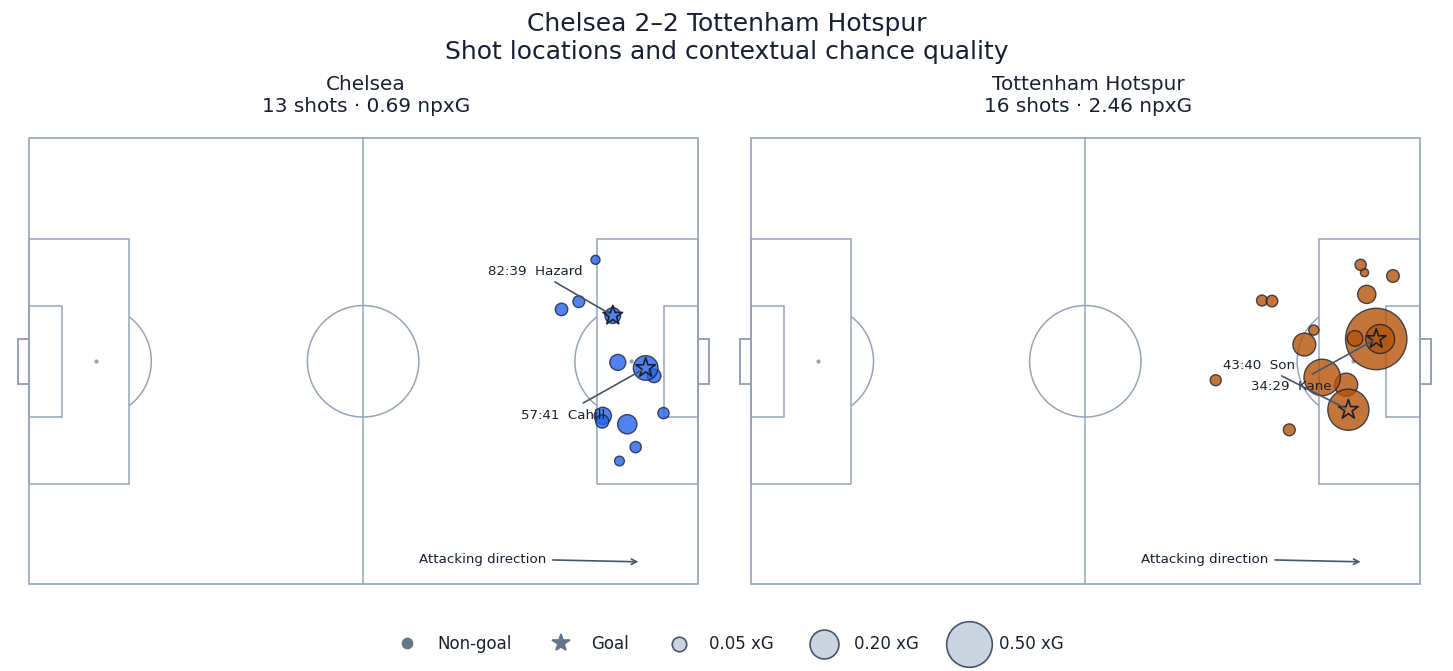

In [8]:
def draw_pitch(ax, attacking_half=False):
    color = "#94a3b8"
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=color, lw=1))
    ax.plot([60, 60], [0, 80], color=color, lw=.9)
    ax.add_patch(Circle((60, 40), 10, fill=False, ec=color, lw=.9))
    for left in (True, False):
        ax.add_patch(Rectangle((0 if left else 102, 18), 18, 44, fill=False, ec=color, lw=.9))
        ax.add_patch(Rectangle((0 if left else 114, 30), 6, 20, fill=False, ec=color, lw=.9))
        ax.add_patch(Rectangle((-2 if left else 120, 36), 2, 8, fill=False, ec=color, lw=1.2))
        ax.plot(12 if left else 108, 40, ".", color=color, ms=3)
        ax.add_patch(Arc((12 if left else 108, 40), 20, 20,
                         theta1=307 if left else 127, theta2=413 if left else 233,
                         ec=color, lw=.9))
    ax.set(xlim=(55 if attacking_half else -3, 124), ylim=(83, -3), aspect="equal")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), layout="constrained")
for ax, team in zip(axes, team_order):
    draw_pitch(ax)
    team_shots = shots.loc[shots["team"].eq(team)]
    ax.scatter(team_shots["shot_x"], team_shots["shot_y"], s=team_shots["model_xg"] * 1500,
               color=team_colors[team], edgecolor="#172033", lw=.8, alpha=.8, zorder=3)
    goals = team_shots.loc[team_shots["is_goal"]]
    ax.scatter(goals["shot_x"], goals["shot_y"], s=150, marker="*", facecolors="none",
               edgecolors="#172033", lw=1, zorder=4)
    for number, row in enumerate(team_shots.loc[team_shots["is_goal"]].itertuples()):
        ax.annotate(f"{row.clock}  {row.player.split()[-1]}", (row.shot_x, row.shot_y),
                    xytext=(-75, -30 if number % 2 == 0 else 25), textcoords="offset points",
                    fontsize=8, arrowprops={"arrowstyle": "-", "color": "#475569"}, zorder=4)
    ax.set_title(f"{team}\n{int(summary.loc[team, 'shots'])} shots · {summary.loc[team, 'npxg']:.2f} npxG")
    ax.annotate("Attacking direction", xy=(110, 76), xytext=(70, 76), fontsize=8,
                arrowprops={"arrowstyle": "->", "color": "#475569"})
handles = [Line2D([], [], ls="", marker="o", color="#64748b", label="Non-goal"),
           Line2D([], [], ls="", marker="*", color="#64748b", markersize=11, label="Goal")]
for probability in [.05, .20, .50]:
    handles.append(plt.scatter([], [], s=probability*1500, color="#cbd5e1", ec="#475569", label=f"{probability:.2f} xG"))
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(.5, -.02))
fig.suptitle(f"{match_title}\nShot locations and contextual chance quality", fontsize=15)
figures["shot_maps"] = fig
plt.show()
plt.close(fig)


### 8. Cumulative xG timeline

A step occurs when a shot is taken. Stars mark observed non-penalty goals at the team's cumulative
xG level. A rising line measures accumulated chance value, not possession or the score itself.

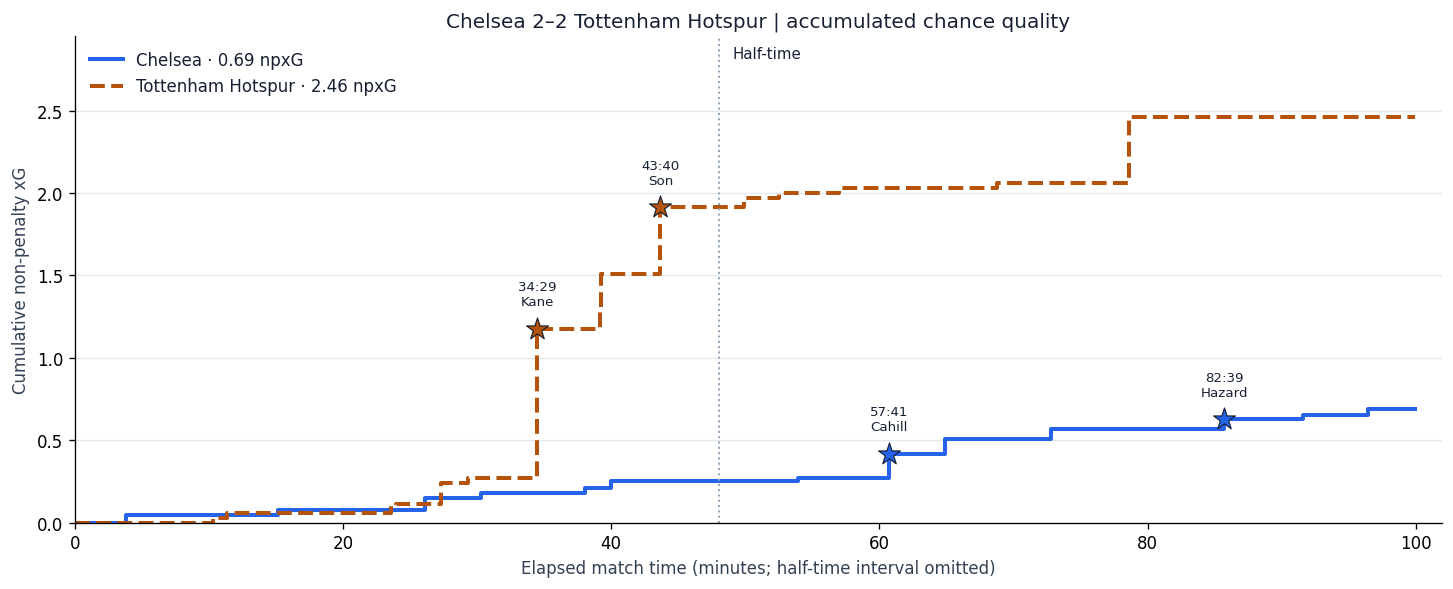

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.8), layout="constrained")
for team in team_order:
    team_shots = shots.loc[shots["team"].eq(team)]
    xs = np.r_[0., team_shots["elapsed_minute"].to_numpy(), full_time]
    ys = np.r_[0., team_shots["cumulative_xg"].to_numpy(), summary.loc[team, "npxg"]]
    ax.step(xs, ys, where="post", color=team_colors[team], ls=team_styles[team], lw=2.4,
            label=f"{team} · {summary.loc[team, 'npxg']:.2f} npxG")
    goals = team_shots.loc[team_shots["is_goal"]]
    ax.scatter(goals["elapsed_minute"], goals["cumulative_xg"], marker="*", s=190,
               color=team_colors[team], edgecolor="#172033", lw=.7, zorder=4)
    for row in goals.itertuples():
        ax.annotate(f"{row.clock}\n{row.player.split()[-1]}", (row.elapsed_minute, row.cumulative_xg),
                    xytext=(0, 14), textcoords="offset points", ha="center", fontsize=8)
    np.testing.assert_allclose(ys[-1], team_shots["model_xg"].sum(), rtol=0, atol=1e-12)
ax.axvline(half_time, color="#94a3b8", ls=":", lw=1.2)
ax.text(half_time + 1, .98, "Half-time", transform=ax.get_xaxis_transform(), va="top", fontsize=9)
ax.set(xlim=(0, full_time + 2), ylim=(0, summary["npxg"].max() * 1.20),
       xlabel="Elapsed match time (minutes; half-time interval omitted)", ylabel="Cumulative non-penalty xG",
       title=f"{match_title} | accumulated chance quality")
ax.grid(axis="y", color="#e2e8f0", lw=.8)
ax.legend(loc="upper left", frameon=False)
figures["xg_timeline"] = fig
plt.show()
plt.close(fig)


### 9. Compare the two halves

Use the same probability scale for both teams. The labels include shot counts, so a change in
chance volume can be distinguished from a change in average shot quality.

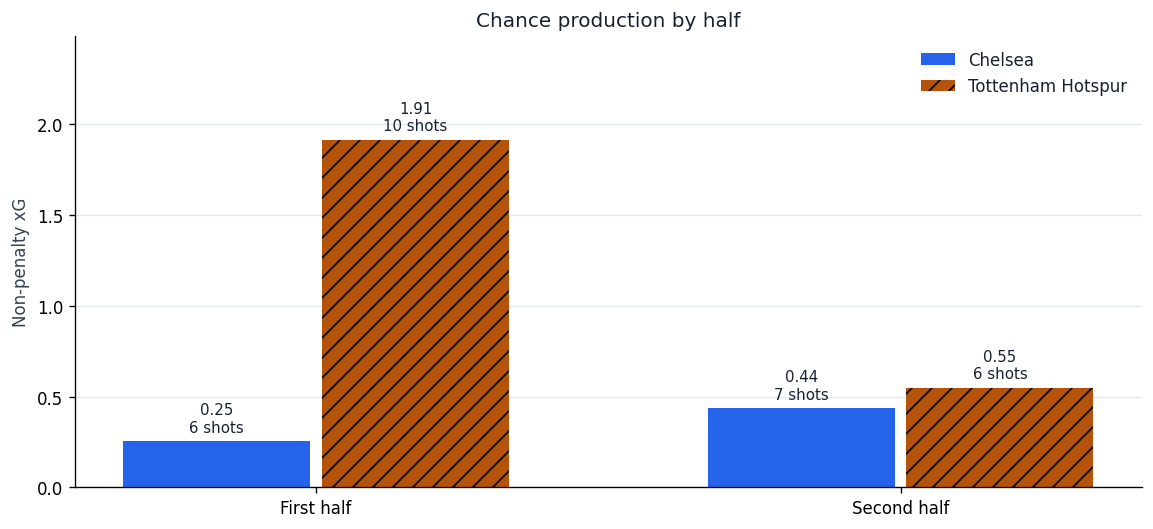

In [10]:
half_summary = shots.groupby(["team", "period"]).agg(npxg=("model_xg", "sum"), shots=("shot_id", "size"))
half_index = pd.MultiIndex.from_product([team_order, [1, 2]], names=["team", "period"])
half_summary = half_summary.reindex(half_index, fill_value=0)
np.testing.assert_allclose(half_summary["npxg"].sum(), summary["npxg"].sum(), rtol=0, atol=1e-12)
fig, ax = plt.subplots(figsize=(9.5, 4.3), layout="constrained")
positions = np.arange(2)
for number, team in enumerate(team_order):
    values = half_summary.loc[team]
    bars = ax.bar(positions + (number - .5) * .34, values["npxg"], width=.32,
                  color=team_colors[team], hatch="" if number == 0 else "//", label=team)
    ax.bar_label(bars, labels=[f"{value:.2f}\n{int(count)} shots" for value,count in zip(values["npxg"],values["shots"])],
                 padding=4, fontsize=9)
ax.set(xticks=positions, xticklabels=["First half", "Second half"], ylabel="Non-penalty xG",
       ylim=(0, half_summary["npxg"].max() * 1.3), title="Chance production by half")
ax.legend(frameon=False)
ax.grid(axis="y", color="#e2e8f0", lw=.8)
ax.set_axisbelow(True)
figures["halves"] = fig
plt.show()
plt.close(fig)


### 10. Inspect the highest-value chances

Rank by the project model, keeping StatsBomb values beside it. Probabilities reflect chance quality,
so a high-ranked miss and a low-ranked goal are both possible. The differences are descriptive examples,
not a test of which model is more accurate on an individual shot.

,Clock,Team,Player,Outcome,Body part,Model xG,StatsBomb xG
1,34:29,Tottenham Hotspur,Harry Kane,Goal,Left Foot,0.906,0.912
2,43:40,Tottenham Hotspur,Heung-Min Son,Goal,Right Foot,0.407,0.471
3,75:33,Tottenham Hotspur,Ryan Mason,Saved,Right Foot,0.319,0.251
4,39:13,Tottenham Hotspur,Heung-Min Son,Blocked,Left Foot,0.201,0.182
5,57:41,Chelsea,Gary Cahill,Goal,Left Foot,0.146,0.088
6,39:10,Tottenham Hotspur,Erik Lamela,Blocked,Left Foot,0.128,0.090
7,27:17,Tottenham Hotspur,Heung-Min Son,Off T,Left Foot,0.126,0.092
8,61:52,Chelsea,Willian Borges da Silva,Saved,Left Foot,0.089,0.099
9,75:35,Tottenham Hotspur,Christian Dannemann Eriksen,Blocked,Left Foot,0.080,0.060
10,26:06,Chelsea,Francesc Fàbregas i Soler,Off T,Right Foot,0.071,0.086


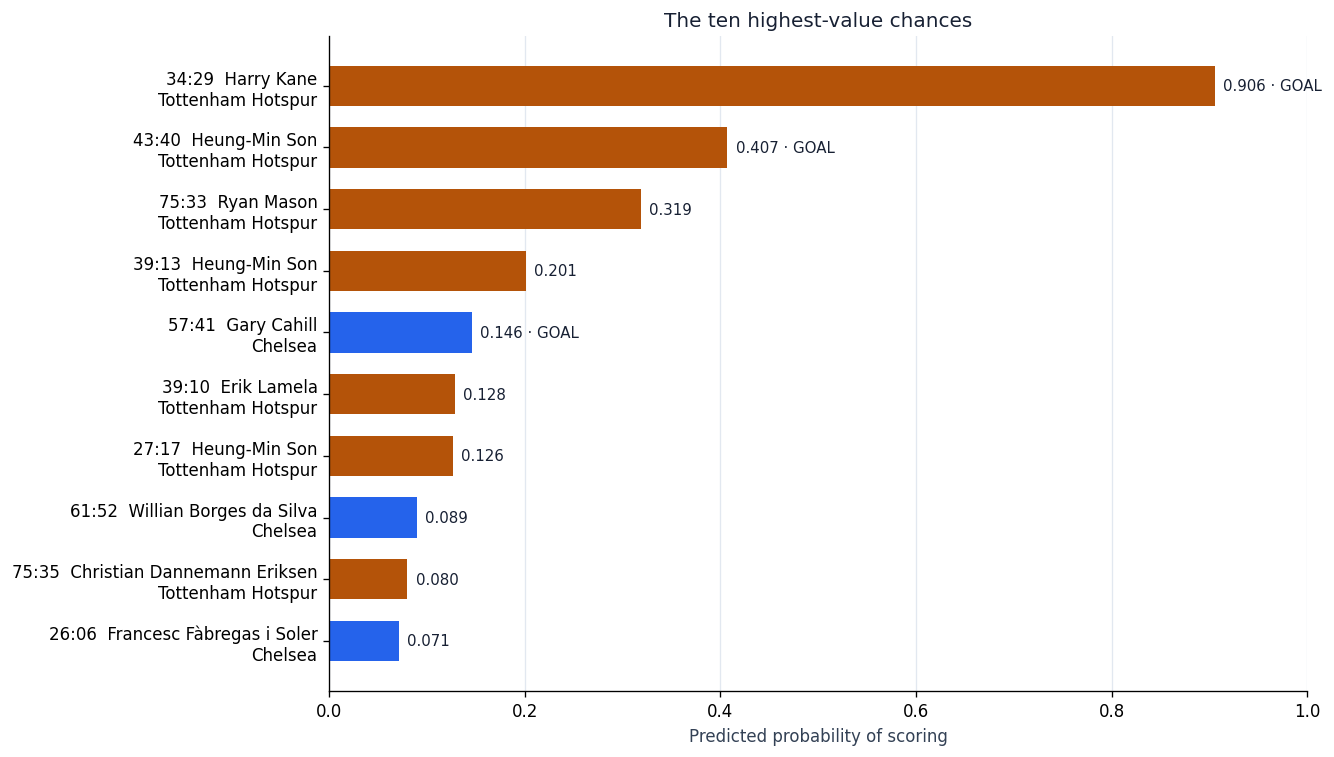

In [11]:
top_chances = shots.nlargest(10, "model_xg").copy()
chance_table = top_chances[["clock", "team", "player", "outcome", "body_part", "model_xg", "statsbomb_xg"]].rename(columns={
    "clock": "Clock", "team": "Team", "player": "Player", "outcome": "Outcome",
    "body_part": "Body part", "model_xg": "Model xG", "statsbomb_xg": "StatsBomb xG",
}).reset_index(drop=True)
chance_table.index += 1
display(chance_table.round({"Model xG": 3, "StatsBomb xG": 3}))

fig, ax = plt.subplots(figsize=(11, 6.2), layout="constrained")
labels = [f"{row.clock}  {row.player}\n{row.team}" for row in top_chances.itertuples()]
bars = ax.barh(np.arange(len(top_chances)), top_chances["model_xg"],
               color=top_chances["team"].map(team_colors), height=.65)
ax.bar_label(bars, labels=[f"{row.model_xg:.3f}" + (" · GOAL" if row.is_goal else "") for row in top_chances.itertuples()],
             padding=5, fontsize=9)
ax.set(yticks=np.arange(len(labels)), yticklabels=labels, xlabel="Predicted probability of scoring",
       xlim=(0, min(1., top_chances["model_xg"].max() * 1.33)), title="The ten highest-value chances")
ax.invert_yaxis()
ax.grid(axis="x", color="#e2e8f0", lw=.8)
ax.set_axisbelow(True)
figures["top_chances"] = fig
plt.show()
plt.close(fig)


### 11. Freeze frames for a goal and a miss from each team

Select each team's highest-xG goal and highest-xG non-goal. These are deliberately selected cases,
not a representative sample. Freeze frames contain visible players around the shot and are not
complete tracking data. A missing frame is labeled as unavailable rather than treated as an empty defense.

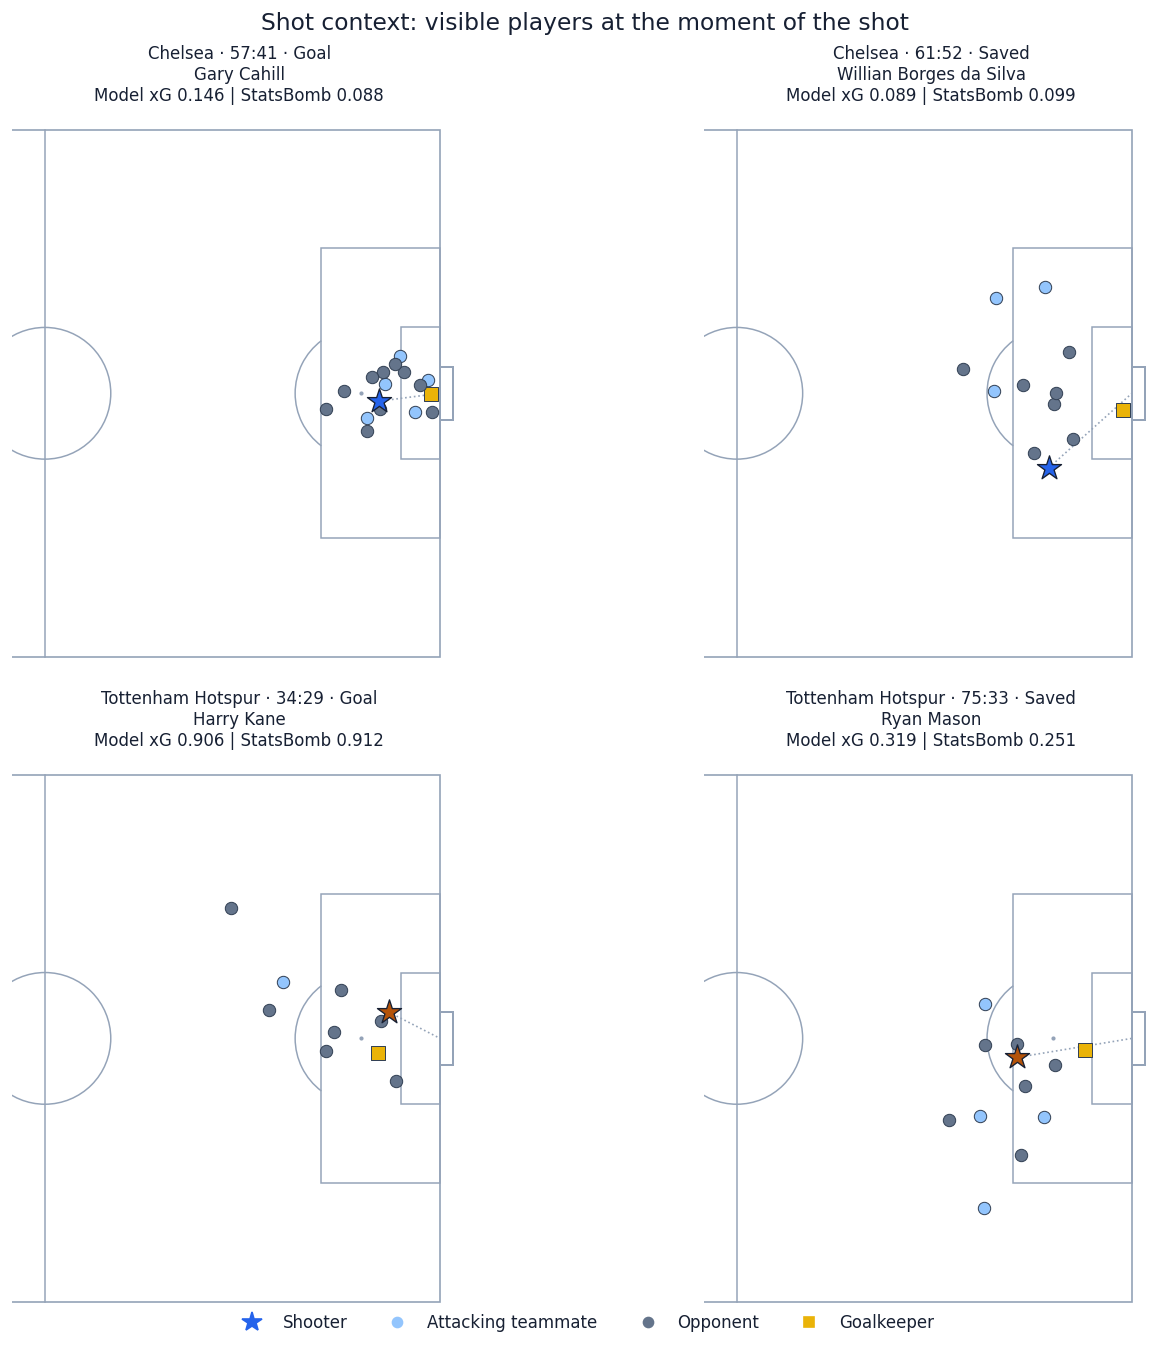

In [12]:
selected_cases = []
for team in team_order:
    for goal in (True, False):
        candidates = shots.loc[shots["team"].eq(team) & shots["is_goal"].eq(goal)]
        if not candidates.empty:
            selected_cases.append(candidates.nlargest(1, "model_xg").iloc[0])

fig, axes = plt.subplots(2, 2, figsize=(11.5, 11), layout="constrained")
for ax, case in zip(axes.flat, selected_cases):
    draw_pitch(ax, attacking_half=True)
    frame = shot_events[case["shot_id"]]["shot"].get("freeze_frame")
    if frame is None:
        ax.text(85, 10, "Freeze frame unavailable", ha="center", fontsize=10)
    else:
        for player in frame:
            location = player.get("location")
            if not isinstance(location, list) or len(location) != 2 or not np.isfinite(location).all():
                continue
            is_keeper = (player.get("position") or {}).get("id") == 1
            marker = "s" if is_keeper else "o"
            color = "#eab308" if is_keeper else ("#93c5fd" if player.get("teammate") is True else "#64748b")
            ax.scatter(*location, s=80 if is_keeper else 55, marker=marker, color=color,
                       edgecolor="#334155", lw=.6, zorder=3)
    ax.plot([case["shot_x"], 120], [case["shot_y"], 40], ls=":", color="#94a3b8", lw=1)
    ax.scatter(case["shot_x"], case["shot_y"], s=230, marker="*", color=team_colors[case["team"]],
               edgecolor="#172033", lw=.8, zorder=5)
    ax.set_title(f"{case['team']} · {case['clock']} · {case['outcome']}\n{case['player']}\n"
                 f"Model xG {case['model_xg']:.3f} | StatsBomb {case['statsbomb_xg']:.3f}", fontsize=10)
for ax in list(axes.flat)[len(selected_cases):]:
    ax.axis("off")
fig.legend(handles=[
    Line2D([],[],ls="",marker="*",ms=12,color="#2563eb",label="Shooter"),
    Line2D([],[],ls="",marker="o",color="#93c5fd",label="Attacking teammate"),
    Line2D([],[],ls="",marker="o",color="#64748b",label="Opponent"),
    Line2D([],[],ls="",marker="s",color="#eab308",label="Goalkeeper"),
], loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(.5,-.015))
fig.suptitle("Shot context: visible players at the moment of the shot", fontsize=14)
figures["freeze_frames"] = fig
plt.show()
plt.close(fig)


## Takeaways

The statements below are generated from the checked shot table. A single match is an illustration
of chance quality and outcomes, not a new model-selection exercise. Summed xG is an expected goal
count and does not directly give a probability of winning. New tuning must not use this test match.

In [13]:
leading_team = summary["npxg"].idxmax()
other_team = next(team for team in team_order if team != leading_team)
gap = summary.loc[leading_team, "npxg"] - summary.loc[other_team, "npxg"]
first_half_goals = shots.loc[shots["period"].eq(1)].groupby("team")["is_goal"].sum().reindex(team_order, fill_value=0)
display(Markdown(
    f"- **Chance quality:** {leading_team} accumulated {gap:.2f} more npxG than {other_team}.\n"
    f"- **Match progression:** the half-time score was {int(first_half_goals.loc[home_name])}–"
    f"{int(first_half_goals.loc[away_name])}; the final score was {full_score[home_name]}–{full_score[away_name]}.\n"
    f"- **Outcome versus expectation:** {home_name} scored "
    f"{summary.loc[home_name, 'goals_minus_npxg']:+.2f} goals relative to npxG, and {away_name} "
    f"{summary.loc[away_name, 'goals_minus_npxg']:+.2f}. These are descriptive match-level differences."
))


- **Chance quality:** Tottenham Hotspur accumulated 1.77 more npxG than Chelsea.
- **Match progression:** the half-time score was 0–2; the final score was 2–2.
- **Outcome versus expectation:** Chelsea scored +1.31 goals relative to npxG, and Tottenham Hotspur -0.46. These are descriptive match-level differences.

### Sources, checks and optional exports

Original data: [StatsBomb Open Data](https://github.com/hudl/open-data), pinned to
`3bfbffe1de5750ebd47d770be0bb924a10cde54f`. Credit StatsBomb when sharing derived work and consult
its [data-use terms](https://github.com/hudl/open-data/blob/3bfbffe1de5750ebd47d770be0bb924a10cde54f/LICENSE.pdf).
The model forecasts come from the project's original frozen test artifact, not from StatsBomb's benchmark.

`SAVE_OUTPUTS = True` saves the five figures, the 29-shot analysis table and a source receipt to
`OUTPUT_DIR`. On Colab these are remote files; download them before committing anything locally.
The cell does not modify any original model, prediction or evaluation file.

In [14]:
source_receipt = {
    "match_id": MATCH_ID, "match_date": match["match_date"], "teams": team_order,
    "data_source": manifest["data_source"], "match_catalogue_url": MATCHES_URL, "events_url": EVENTS_URL,
    "prediction_file": prediction_relative, "prediction_sha256": expected_hash,
    "selected_model": PREDICTION_COLUMN, "eligibility": "shot_type != 'Penalty'",
    "rows": len(shots), "join": "one_to_one_on_shot_id",
    "timeline": "sum of preceding period durations plus current period timestamp; half-time interval omitted",
}
assert len(shots) == len(match_predictions)
assert int(summary["non_penalty_goals"].sum()) == sum(full_score.values())
assert all(np.isclose(shots.loc[shots["team"].eq(team), "cumulative_xg"].iloc[-1], summary.loc[team, "npxg"])
           for team in team_order)
print("Checks passed: frozen hashes, shot IDs, split, team routing, score, timeline and aggregation.")
if SAVE_OUTPUTS:
    output_resolved = OUTPUT_DIR.resolve()
    artifact_resolved = ARTIFACT_ROOT.resolve()
    if output_resolved == artifact_resolved or artifact_resolved in output_resolved.parents:
        raise ValueError("Choose an output directory outside the original artifact root.")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for name, figure in figures.items():
        figure.savefig(OUTPUT_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    shots.to_csv(OUTPUT_DIR / "match_shots.csv", index=False)
    (OUTPUT_DIR / "sources.json").write_text(json.dumps(source_receipt, indent=2), encoding="utf-8")
    print("Saved analysis outputs to", OUTPUT_DIR)
else:
    print("Exports disabled. Original artifacts were only read.")


Checks passed: frozen hashes, shot IDs, split, team routing, score, timeline and aggregation.
Exports disabled. Original artifacts were only read.
